# Member B: Draft value

**Tasks**

- [x] Plot raw mean outcome by pick, then the smoothed baseline (`fit_baseline`). Tune `frac` and justify it. *(sections 3-4: frac = 0.1)*
- [x] Position x pick-tier table of mean surplus with n and bootstrap CIs. Many cells are tiny (see counts): grey them out or merge tiers. *(section 7: n < 10 greyed out)*
- [x] Heatmap. Answer: where does the curve flatten? Which positions beat their slot per tier? *(sections 7 and 9)*
- [x] Check the baseline on a held-out set of classes. *(section 8)*
- [x] Era check: are older classes inflated? *(section 6)*

**Reproduce the heatmap table in your own notebook:**
```python
from src.features.outcome import get_outcome
from src.features.baseline import fit_baseline, add_surplus, surplus_table

df['outcome'] = get_outcome(df).fillna(0)   # fillna(0) is temporary, see section 1
df = add_surplus(df, fit_baseline(df))
table = surplus_table(df)                   # position x tier: n, mean, 95% CI, small, clear
```

See `docs/week1_tasks.md` and the project plan for details. Reusable code is in
`src/features/baseline.py`. **Answers are in section 9; flags for teammates in section 10.**

## 0. Setup

Imports, plot style, and loading the master table. `autoreload` re-imports
`src/features/baseline.py` every time a cell runs, so edits there show up without
restarting the kernel. All shared definitions (class window, tiers, paths) come
from `src/utils.py`; nothing is hardcoded here.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..')  # so `import src...` works from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import PROCESSED, CLASS_MIN, CLASS_MAX
from src.features.outcome import get_outcome  # the ONE outcome definition (Vincent)

In [2]:
# Plot style used throughout this notebook: thin marks, light grid, one accent colour.
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#8a8984'
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.8,
    'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
})

In [3]:
master = pd.read_parquet(PROCESSED / 'master.parquet')

# Keep only the agreed analysis window (defined once, in src/utils.py).
df = master[master['season'].between(CLASS_MIN, CLASS_MAX)].copy()
# Always take the outcome from get_outcome(), so changes to outcome.py flow through here.
df['outcome'] = get_outcome(df)
print(df.shape, '| classes:', df['season'].min(), '-', df['season'].max())

(3320, 53) | classes: 2010 - 2022


## 1. Missing outcomes (temporary fix)

Some players have no `outcome` (currently w_av, from `get_outcome()`). If they simply never played an NFL snap,
their true outcome is 0 AV, not "unknown". Leaving them as NaN means `mean()`
silently skips them, which **inflates** late-pick averages (the busts disappear).
First, confirm that every missing outcome really is a player with no games.

In [4]:
missing = df['outcome'].isna()
print(f'missing outcome: {missing.sum()} of {len(df)} ({missing.mean():.1%})')

# Do any of them have NFL games recorded? (games NaN or 0 both mean "never played")
played = df.loc[missing, 'games'].fillna(0) > 0
print('missing-outcome players with games > 0:', played.sum())

# Where in the draft are they?
df.loc[missing, 'round'].value_counts().sort_index()

missing outcome: 239 of 3320 (7.2%)
missing-outcome players with games > 0: 0


round
2      2
3     10
4     17
5     31
6     67
7    112
Name: count, dtype: int64

How much does that matter? Compare mean outcome by round with the NaNs dropped
(what `mean()` does by default) vs. counted as 0.

In [5]:
by_round = pd.DataFrame({
    'mean_nan_dropped': df.groupby('round')['outcome'].mean(),
    'mean_nan_as_0':    df.groupby('round')['outcome'].apply(lambda s: s.fillna(0).mean()),
})
by_round['inflation_%'] = 100 * (by_round['mean_nan_dropped'] / by_round['mean_nan_as_0'] - 1)
by_round.round(1)

,mean_nan_dropped,mean_nan_as_0,inflation_%
round,,,
1,39.4,39.4,0.0
2,25.9,25.8,0.5
3,19.4,19.0,2.1
4,13.5,13.0,3.6
5,11.5,10.7,7.0
6,7.9,6.9,14.9
7,6.1,4.8,26.7


In [6]:
# TEMPORARY (notebook only): players with no outcome never played, so their true
# outcome is 0 AV. get_outcome() in src/features/outcome.py still returns NaN for them.
# FLAG FOR VINCENT (Member C): handle this in outcome.py, then delete this line.
df['outcome'] = df['outcome'].fillna(0)
assert df['outcome'].notna().all()

## 2. How many players per pick? (the tail problem)

Each class has one player at each pick, so with 13 classes a "full" pick has n = 13.
Classes run 253-262 picks long (compensatory picks vary), so the very end of the
draft has only a few players per pick. A mean of 1-2 players is pure noise, and it
sits at the edge of the curve where a smoother has the least data to lean on.

In [7]:
n_classes = df['season'].nunique()
n_per_pick = df.groupby('pick').size()

# Last pick before coverage first drops below one player per class.
first_short = n_per_pick[n_per_pick < n_classes].index.min()
MAX_PICK = int(first_short - 1)

print(f'{n_classes} classes; picks 1-{MAX_PICK} all have n = {n_classes}')
print('tail picks and their n:')
n_per_pick.loc[MAX_PICK + 1:].to_frame('n').T

13 classes; picks 1-253 all have n = 13
tail picks and their n:


pick,254,255,256,257,258,259,260,261,262
n,10,7,5,2,2,2,1,1,1


**Decision:** cap the pick at `MAX_PICK`. Players taken after it are treated as
if picked at `MAX_PICK` (their outcome is kept, only their pick is clipped).
Nobody is thrown away, but no single player can bend the end of the curve, and
a pick-262 player is compared against the same expectation as a pick-253 player,
which is reasonable: by then the value curve is flat.

In [8]:
df['pick_capped'] = df['pick'].clip(upper=MAX_PICK)
print('players whose pick was capped:', (df['pick'] > MAX_PICK).sum())

players whose pick was capped: 31


## 3. Raw mean outcome by pick

The unsmoothed picture: the mean w_av of the players taken at each pick.
The bottom panel shows how many players each mean is based on (separate panel,
not a second y-axis, so neither scale is misread).

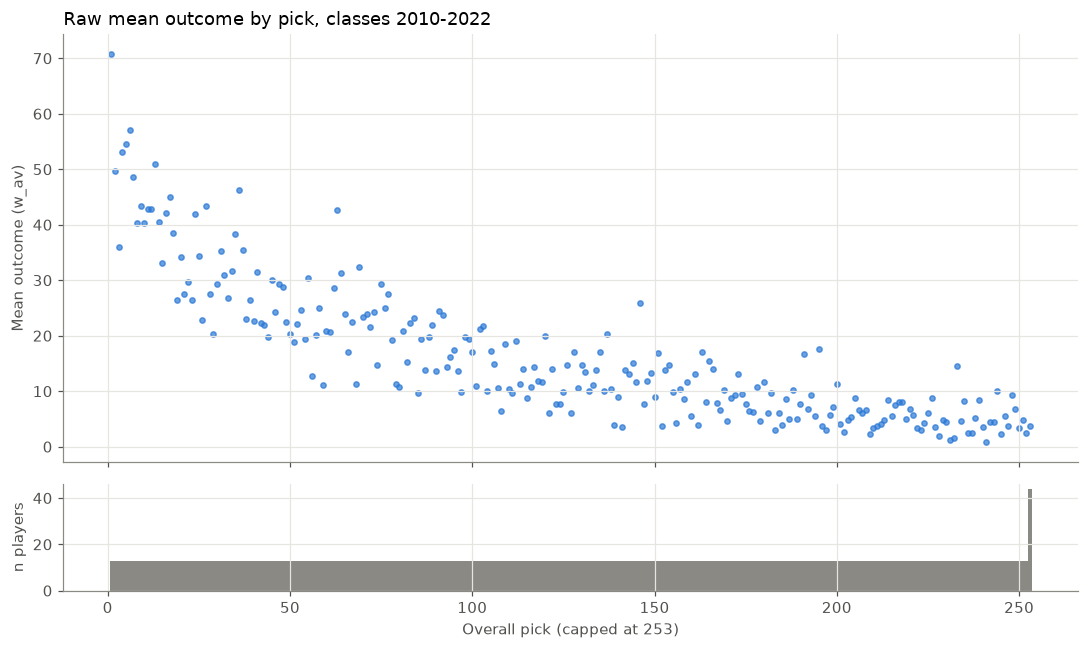

In [9]:
raw = df.groupby('pick_capped')['outcome'].agg(['mean', 'size'])

fig, (ax, ax_n) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                               gridspec_kw={'height_ratios': [4, 1]})

ax.scatter(raw.index, raw['mean'], s=12, color=BLUE, alpha=0.7)
ax.set_ylabel('Mean outcome (w_av)')
ax.set_title(f'Raw mean outcome by pick, classes {CLASS_MIN}-{CLASS_MAX}', loc='left')

ax_n.bar(raw.index, raw['size'], width=1, color=GREY)
ax_n.set_ylabel('n players')
ax_n.set_xlabel(f'Overall pick (capped at {MAX_PICK})')

plt.tight_layout()
plt.show()

In [10]:
# Summary at a few landmark picks: how fast does value fall?
landmarks = [1, 5, 10, 16, 32, 50, 64, 100, 150, 200, MAX_PICK]
raw.loc[landmarks, 'mean'].round(1).to_frame('mean_outcome').T

pick_capped,1,5,10,16,32,50,64,100,150,200,253
mean_outcome,70.8,54.5,40.2,42.1,30.9,20.3,31.4,17.1,9.0,11.2,3.8


**What the raw curve shows**

- **Missing outcomes were biasing the late rounds.** All 239 missing-outcome players have
  0 games, and 179 of them are rounds 6-7. Dropping them instead of counting them as 0
  overstated round-7 value by ~27% and round-6 by ~15%, but barely touched rounds 1-2.
  This would have made late picks look like better value than they are.
- **Value falls steeply, then slowly.** Mean w_av is ~71 at pick 1, ~40 by pick 10, ~30
  around pick 32, ~20 by pick 50, then drifts down to ~10 by pick 150 and ~4 at the end.
  Most of the drop happens in roughly the first 50 picks.
- **Single picks are very noisy.** Each point is the mean of only 13 players, so one star
  moves it a lot: pick 64 (31.4) sits far above its neighbours, and pick 16 (42.1) beats
  pick 10 (40.2). This is why we smooth (next section) and why the position comparison
  uses tiers, not single picks.
- **Tail handled:** picks 1-253 all have n = 13; the 31 players taken after pick 253 are
  pooled at 253, so no 1-player pick can bend the end of the curve.


## 4. Smoothing the curve: tuning LOWESS `frac`

LOWESS draws the curve by sliding a window along the x-axis and fitting a small
weighted straight line inside each window. `frac` is the **share of all players**
in each window. Because every pick has about 13 players, `frac` x 253 is roughly the
window width in picks: `frac = 0.1` looks at about 25 neighbouring picks, and
`frac = 0.5` looks at about 125.

- **Too small:** the curve chases noise (e.g. the pick-64 spike).
- **Too large:** the curve can't bend fast enough for the steep drop in picks 1-50,
  so it **underrates the top picks** and overrates picks 20-50. That's the region
  that matters most for draft value, so this error is costly.

We fit with `fit_baseline` from `src/features/baseline.py`; its `max_pick` argument
applies the same pick-253 cap as section 2.

In [11]:
from src.features.baseline import fit_baseline

FRACS = [0.05, 0.1, 0.2, 0.3, 0.5]
curves = {f: fit_baseline(df, frac=f, max_pick=MAX_PICK) for f in FRACS}

Every candidate plotted over the raw means. The left panel shows the whole draft;
the right panel zooms in on the first two rounds, where the candidates disagree most.

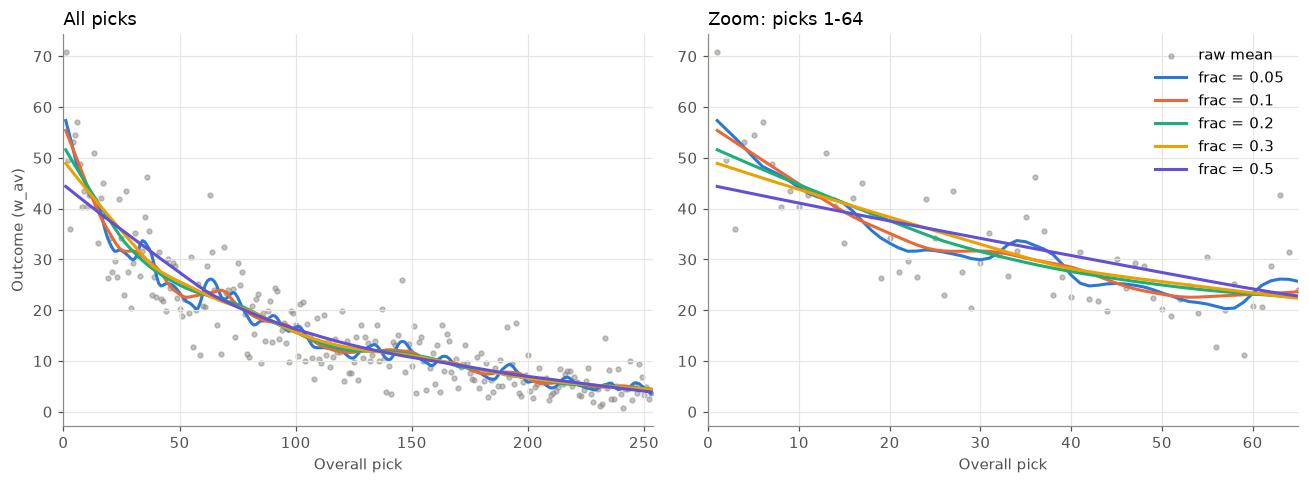

In [12]:
FRAC_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#6250d6']  # fixed order

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, xmax in zip(axes, [MAX_PICK, 64]):
    ax.scatter(raw.index, raw['mean'], s=10, color=GREY, alpha=0.5, label='raw mean')
    for f, c in zip(FRACS, FRAC_COLORS):
        ax.plot(curves[f].index, curves[f].values, color=c, lw=2, label=f'frac = {f}')
    ax.set_xlim(0, xmax + 1)
    ax.set_xlabel('Overall pick')
axes[0].set_ylabel('Outcome (w_av)')
axes[0].set_title('All picks', loc='left')
axes[1].set_title('Zoom: picks 1-64', loc='left')
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

The same comparison as numbers: each curve's value at a few landmark picks next to
the raw tier average. The tier average for picks 1-5 is a fair check of how well
each curve handles the top of the draft.

In [13]:
landmark_tbl = pd.DataFrame({f'frac {f}': curves[f].loc[[1, 5, 10, 32, 64, 100, 200]]
                             for f in FRACS}).round(1)
landmark_tbl.index.name = 'pick'
landmark_tbl

,frac 0.05,frac 0.1,frac 0.2,frac 0.3,frac 0.5
pick,,,,,
1,57.3,55.4,51.6,48.9,44.4
5,50.1,50.7,48.5,46.6,42.9
10,44.2,44.9,44.7,43.8,41.1
32,31.3,31.4,30.6,31.9,33.5
64,26.1,23.5,22.7,22.5,23.0
100,16.6,15.9,15.6,15.7,16.3
200,5.8,6.7,6.7,6.6,7.0


In [14]:
# Mean of raw outcomes vs. mean of each curve, within each early pick range.
# A good curve should roughly match the raw average inside each range.
ranges = {'1-5': (1, 5), '6-15': (6, 15), '16-32': (16, 32), '33-64': (33, 64)}
rows = {}
for name, (lo, hi) in ranges.items():
    in_range = df['pick_capped'].between(lo, hi)
    row = {'raw': df.loc[in_range, 'outcome'].mean()}
    for f in FRACS:
        row[f'frac {f}'] = curves[f].loc[df.loc[in_range, 'pick_capped']].mean()
    rows[name] = row
pd.DataFrame(rows).T.round(1)

,raw,frac 0.05,frac 0.1,frac 0.2,frac 0.3,frac 0.5
1-5,52.8,53.8,53.0,50.0,47.7,43.6
6-15,44.0,44.2,44.3,44.4,43.5,40.9
16-32,32.7,32.6,33.5,35.1,36.2,36.2
33-64,25.9,25.6,25.4,25.7,26.2,28.0


### Scoring each `frac` on held-out classes

Looking at plots is subjective, so we also score each `frac` objectively:
**leave-one-class-out**. For each of the 13 draft classes, we fit the curve on the
other 12 classes and measure how far off it is for the held-out class's players
(RMSE, in AV). A curve that chases noise fits its training classes well but does
worse on a class it has never seen.

As a reference we also score the **unsmoothed raw pick mean** (the mean of the
other 12 players at the same pick). This is the "no smoothing at all" extreme.

Player outcomes vary a lot even at the same pick, so every RMSE will be large and
the differences between candidates small. What matters is the **ranking**.

In [15]:
def loco_rmse(df, frac=None):
    """Leave-one-class-out RMSE. frac=None scores the unsmoothed raw pick mean."""
    sq_errors = []
    for season in sorted(df['season'].unique()):
        train, test = df[df['season'] != season], df[df['season'] == season]
        if frac is None:
            curve = train.groupby('pick_capped')['outcome'].mean()
        else:
            curve = fit_baseline(train, frac=frac, max_pick=MAX_PICK)
        pred = curve.reindex(test['pick_capped']).to_numpy()
        sq_errors.append((test['outcome'].to_numpy() - pred) ** 2)
    return np.sqrt(np.concatenate(sq_errors).mean())


scores = pd.Series({'raw pick mean': loco_rmse(df)} |
                   {f'frac {f}': loco_rmse(df, f) for f in FRACS}, name='held-out RMSE')
scores.round(3).to_frame()

,held-out RMSE
raw pick mean,17.037
frac 0.05,16.634
frac 0.1,16.616
frac 0.2,16.617
frac 0.3,16.640
frac 0.5,16.707


### Choice of `frac`: **0.1** (a window of about 25 picks)

1. **Held-out error:** 0.1 and 0.2 tie for the best leave-one-class-out RMSE (16.62 AV).
   All smoothed curves beat the unsmoothed raw pick mean (17.04), which confirms that
   single-pick means overfit. The spread among 0.05-0.3 is tiny, though, because
   player-to-player noise dominates. RMSE rules out the extremes (no smoothing, 0.5)
   but can't choose among the rest on its own.
2. **Bias at the top of the draft decides it.** Inside each early range, a good curve
   should match the raw average. frac 0.1 does (1-5: 53.0 vs raw 52.8; 16-32: 33.5 vs
   32.7). Larger windows can't follow the steep early drop. At 0.3 (the old default) the
   curve **underrates picks 1-5 by ~5 AV and overrates picks 16-32 by ~3.5 AV**. That
   error would show up in the heatmap as fake positive surplus for every top-5 pick and
   fake negative surplus for late-first-rounders, whatever the position.
3. **0.05 is too wiggly:** it bends toward single noisy picks (bumps near picks 35 and
   64) without any gain in held-out error.

Trade-off accepted: 0.1 is slightly wavy in places (e.g. a small flat stretch around
picks 45-65), but that matters far less than a systematic bias in the first round.


In [16]:
FRAC = 0.1  # chosen above; used for the baseline in every later section
baseline = curves[FRAC]
baseline.loc[[1, 5, 15, 32, 64, 100, 200, MAX_PICK]].round(1).to_frame('expected_outcome').T

pick,1,5,15,32,64,100,200,253
expected_outcome,55.4,50.7,39.3,31.4,23.5,15.9,6.7,4.3


## 5. The baseline functions in `src/features/baseline.py`

Everything above was exploration. The reusable version lives in
`src/features/baseline.py`, so teammates (and Layer 2) use the exact same curve:

| function | what it does |
|---|---|
| `fit_baseline(df)` | fits the shared LOWESS curve (frac 0.1, tail capped) -> Series: pick -> expected outcome |
| `add_surplus(df, baseline)` | adds `expected` (curve value at the player's pick) and `surplus` = outcome - expected |
| `bootstrap_ci(values)` | 95% confidence interval for a mean, by resampling |
| `last_full_pick(df)` | the last pick every class reaches (253 here); used as the default cap |

First, check the module's defaults reproduce the choices made above.

In [17]:
from src.features.baseline import add_surplus, bootstrap_ci, last_full_pick

assert last_full_pick(df) == MAX_PICK          # same cap as section 2
baseline = fit_baseline(df)                    # defaults: frac=0.1, cap at 253
assert np.allclose(baseline, curves[FRAC])     # same curve as section 4
print('baseline covers picks', baseline.index.min(), '-', baseline.index.max())

baseline covers picks 1 - 253


Add `expected` and `surplus` to every player. Note we pass the **original** `pick`
column: `add_surplus` applies the cap itself, so teammates don't need `pick_capped`.

In [18]:
df = add_surplus(df, baseline)
df[['season', 'pick', 'player_name', 'pos_group', 'outcome', 'expected', 'surplus']].head(8).round(1)

,season,pick,player_name,pos_group,outcome,expected,surplus
0,2010,1,Sam Bradford,QB,44.0,55.4,-11.4
1,2010,2,Ndamukong Suh,IDL,100.0,54.2,45.8
2,2010,3,Gerald McCoy,IDL,69.0,53.0,16.0
3,2010,4,Trent Williams,OT,109.0,51.9,57.1
4,2010,5,Eric Berry,S,50.0,50.7,-0.7
5,2010,6,Russell Okung,OT,56.0,49.5,6.5
6,2010,7,Joe Haden,CB,62.0,48.4,13.6
7,2010,8,Rolando McClain,LB,25.0,47.2,-22.2


**Sanity check.** The curve is meant to be the average outcome at each pick, so
surplus should average about 0 overall *and within every pick tier*. A tier far from 0
would mean the curve is biased there (this is exactly what went wrong with frac 0.3 in
the top 5). The CI column uses `bootstrap_ci`; if it contains 0, the tier is
consistent with "no bias".

In [19]:
def summarize(s):
    lo, hi = bootstrap_ci(s)
    return pd.Series({'n': len(s), 'mean_surplus': s.mean(), 'ci_low': lo, 'ci_high': hi})

check = pd.concat({'ALL': summarize(df['surplus'])}, axis=1).T
check = pd.concat([check, df.groupby('pick_tier', observed=True)['surplus'].apply(summarize).unstack()])
check.round(2)

,n,mean_surplus,ci_low,ci_high
ALL,3320.0,-0.05,-0.58,0.51
1-5,65.0,-0.22,-6.80,7.01
6-15,130.0,-0.36,-4.59,4.01
16-32,221.0,-0.81,-3.79,2.06
33-64,416.0,0.57,-1.42,2.58
65-100,468.0,-0.31,-2.08,1.41
101+,2020.0,-0.01,-0.54,0.54


## 6. Era check: are older classes inflated?

`w_av` is **career-to-date**. A 2010 pick has had up to 16 seasons to pile up AV;
a 2022 pick has had 4. So at the same pick, older players should look better just
because they've had more time. Our one shared curve averages over all classes, which
means recent classes will tend to sit *below* it (negative surplus) and older ones
*above* it, for reasons unrelated to position.

Three questions:
1. How big is the effect? (curves for early vs. late classes)
2. Which classes are affected? (mean surplus by class)
3. Does it distort the **position** comparison, which is what we actually care about?

### 6a. Early vs. late curves

Fit the same baseline separately on the four oldest and four newest classes.

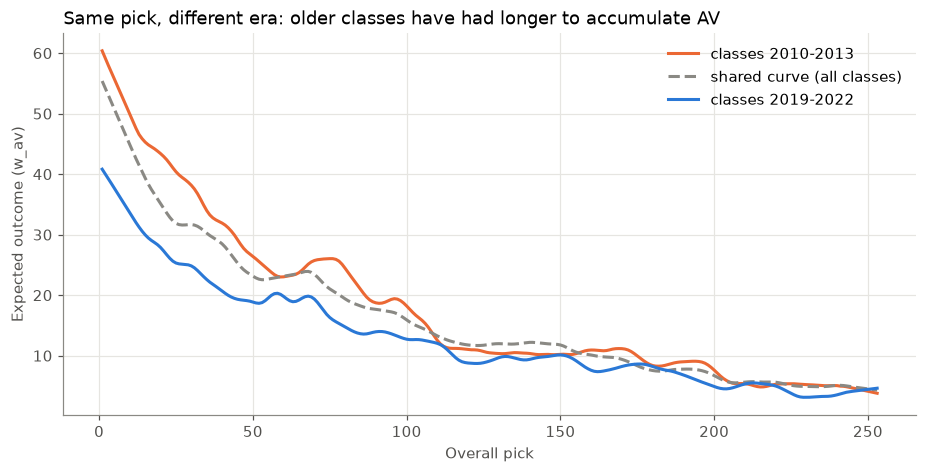

In [20]:
EARLY, LATE = (2010, 2013), (2019, 2022)
early_curve = fit_baseline(df[df['season'].between(*EARLY)], max_pick=MAX_PICK)
late_curve = fit_baseline(df[df['season'].between(*LATE)], max_pick=MAX_PICK)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(early_curve.index, early_curve, color=ORANGE, lw=2, label=f'classes {EARLY[0]}-{EARLY[1]}')
ax.plot(baseline.index, baseline, color=GREY, lw=2, ls='--', label='shared curve (all classes)')
ax.plot(late_curve.index, late_curve, color=BLUE, lw=2, label=f'classes {LATE[0]}-{LATE[1]}')
ax.set_xlabel('Overall pick')
ax.set_ylabel('Expected outcome (w_av)')
ax.set_title('Same pick, different era: older classes have had longer to accumulate AV', loc='left')
ax.legend(frameon=False)
plt.show()

In [21]:
L = [1, 5, 10, 32, 64, 100, 200]
pd.DataFrame({'early': early_curve[L], 'late': late_curve[L],
              'early / late': early_curve[L] / late_curve[L]}).round(2).T

pick,1,5,10,32,64,100,200
early,60.38,55.67,49.88,36.78,23.46,18.22,7.62
late,40.82,37.64,33.57,24.08,18.97,12.72,4.90
early / late,1.48,1.48,1.49,1.53,1.24,1.43,1.56


### 6b. Mean surplus by draft class

If the shared curve were fair to every class, each class's mean surplus would
hover around 0. The bottom panel uses `to` (last season played) to show what share of
each class was still active in the most recent season: players still playing are
still adding AV.

In [22]:
from src.features.outcome import add_career_length   # Vincent's helper: seasons_possible
from src.utils import LAST_COMPLETE_SEASON

df = add_career_length(df)

by_class = df.groupby('season').agg(
    mean_surplus=('surplus', 'mean'),
    seasons_possible=('seasons_possible', 'first'),
    still_active=('to', lambda s: (s >= LAST_COMPLETE_SEASON).mean()),
)
cis = df.groupby('season')['surplus'].apply(bootstrap_ci)
by_class['ci_low'] = [lo for lo, hi in cis]
by_class['ci_high'] = [hi for lo, hi in cis]
by_class.round(2)

,mean_surplus,seasons_possible,still_active,ci_low,ci_high
season,,,,,
2010,1.71,16,0.01,-0.42,3.95
2011,1.54,15,0.02,-1.02,4.21
2012,2.46,14,0.04,0.05,5.14
2013,0.07,13,0.05,-2.02,2.26
2014,0.89,12,0.07,-1.35,3.02
2015,-0.13,11,0.12,-1.99,1.90
2016,2.30,10,0.22,-0.01,4.70
2017,1.56,9,0.34,-0.40,3.80
2018,2.32,8,0.42,0.57,4.20


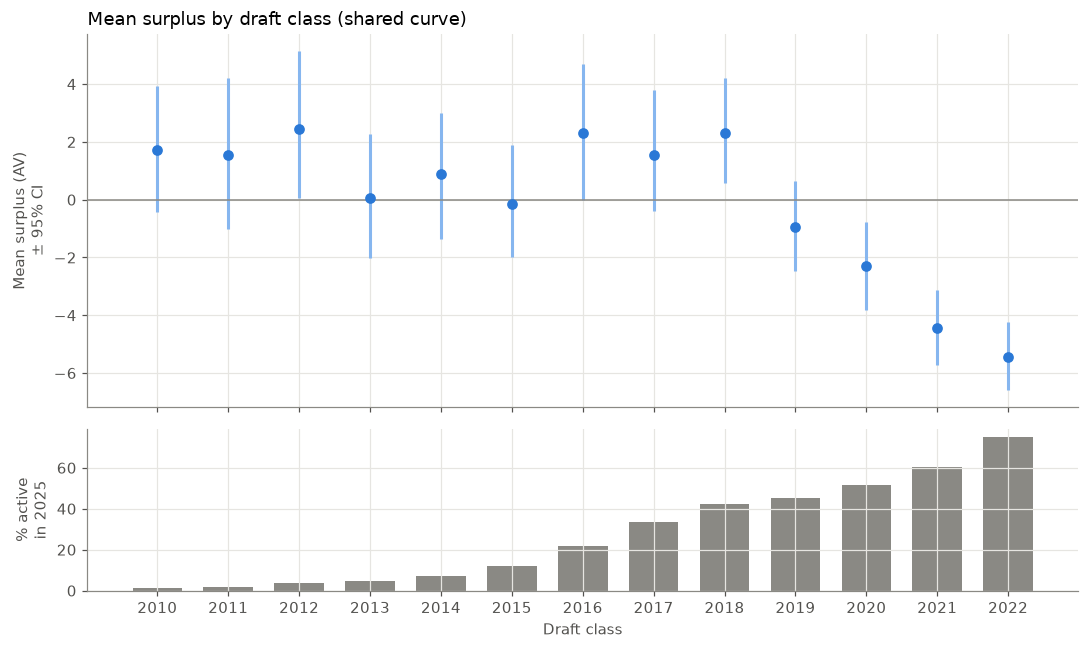

In [23]:
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                              gridspec_kw={'height_ratios': [3, 1.3]})

err = [by_class['mean_surplus'] - by_class['ci_low'], by_class['ci_high'] - by_class['mean_surplus']]
ax.errorbar(by_class.index, by_class['mean_surplus'], yerr=err, fmt='o', color=BLUE,
            ecolor='#86b6ef', elinewidth=2, capsize=0, markersize=6)
ax.axhline(0, color=GREY, lw=1)
ax.set_ylabel('Mean surplus (AV)\n± 95% CI')
ax.set_title('Mean surplus by draft class (shared curve)', loc='left')

ax2.bar(by_class.index, by_class['still_active'] * 100, color=GREY, width=0.7)
ax2.set_ylabel(f'% active\nin {LAST_COMPLETE_SEASON}')
ax2.set_xlabel('Draft class')
ax2.set_xticks(by_class.index)
plt.tight_layout()
plt.show()

### 6c. Does the era effect distort positions?

The era effect only biases a **position** comparison if positions are spread unevenly
across classes. If every position has about the same share of recent (deflated)
classes, the bias hits all positions equally and cancels out when we compare them.

In [24]:
era = pd.cut(df['season'], [2009, 2013, 2018, 2022], labels=['2010-13', '2014-18', '2019-22'])
mix = pd.crosstab(df['pos_group'], era, normalize='index').mul(100).round(0)
mix['mean_class'] = df.groupby('pos_group')['season'].mean().round(1)
mix.sort_values('2019-22')

season,2010-13,2014-18,2019-22,mean_class
pos_group,,,,
EDGE,36.0,42.0,22.0,2015.3
QB,32.0,39.0,29.0,2015.8
TE,36.0,35.0,29.0,2015.5
RB,30.0,40.0,30.0,2016.1
S,32.0,37.0,31.0,2016.0
WR,29.0,41.0,31.0,2016.1
IDL,30.0,39.0,32.0,2016.2
IOL,30.0,37.0,33.0,2016.1
OT,29.0,37.0,34.0,2016.3


### 6d. Candidate fixes

Each fix changes the outcome *before* fitting the baseline, then we recompute
surplus. A good fix should (1) bring every class's mean surplus close to 0 and
(2) keep outcomes in sensible units without distorting real differences between players.

| fix | outcome used | idea | concern |
|---|---|---|---|
| **none** | `w_av` | as is | recent classes deflated |
| **class-scaled** | `w_av / class mean x overall mean` | each class's outcomes are rescaled so every class has the same average; units stay "AV" | assumes era inflation is proportional (6a checks this: early/late ratio is ~1.5 across picks) |
| **within-class percentile** | rank in class, 0-100 | only order within a class matters | throws away magnitude: a superstar QB counts the same as a merely good one |
| **AV per season** | `w_av / seasons_possible` | per-year rate | penalises old classes for normal retirements (a 6-year career divided by 16 seasons) |

This is a **comparison only**. The outcome definition belongs to Vincent (`outcome.py`),
so the rest of this notebook keeps the official `get_outcome()` value; the fixes below
are evidence for a recommendation, not a change to the analysis.

In [25]:
class_mean = df.groupby('season')['outcome'].transform('mean')
candidates = {
    'none (w_av)':   df['outcome'],
    'class-scaled':  df['outcome'] / class_mean * df['outcome'].mean(),
    'percentile':    df.groupby('season')['outcome'].rank(pct=True) * 100,
    'AV per season': df['outcome'] / df['seasons_possible'],
}

class_spread, pos_surplus = {}, {}
for name, values in candidates.items():
    d = df.assign(outcome=values)
    d = add_surplus(d, fit_baseline(d))
    per_class = d.groupby('season')['surplus'].mean()
    # put spread on a common scale: as % of that outcome's overall mean
    class_spread[name] = (per_class.max() - per_class.min()) / d['outcome'].mean() * 100
    pos_surplus[name] = d.groupby('pos_group')['surplus'].mean()

pd.Series(class_spread, name='class mean-surplus range, % of mean outcome').round(1).to_frame()

,"class mean-surplus range, % of mean outcome"
none (w_av),48.9
class-scaled,2.4
percentile,1.6
AV per season,84.7


Now the question that matters: **does the fix change the position ranking?** Mean
surplus by position under each version (units differ by column, so compare signs
and order, not sizes), then the rank correlation between versions (1.0 = identical order).

In [26]:
pos_tbl = pd.DataFrame(pos_surplus)
pos_tbl.sort_values('class-scaled', ascending=False).round(2)

,none (w_av),class-scaled,percentile,AV per season
pos_group,,,,
IOL,3.69,3.90,6.50,0.41
OT,2.27,2.48,3.38,0.27
EDGE,2.63,1.61,2.35,-0.02
LB,0.47,0.81,1.67,0.18
IDL,1.03,0.63,2.35,0.03
RB,-0.21,-0.05,-0.26,0.04
S,-0.07,-0.08,2.93,0.01
QB,-0.28,-0.62,-9.32,-0.02
WR,-1.69,-1.45,-4.33,-0.14


In [27]:
pos_tbl.rank(ascending=False).corr(method='spearman').round(2)

,none (w_av),class-scaled,percentile,AV per season
none (w_av),1.00,0.97,0.86,0.82
class-scaled,0.97,1.00,0.84,0.90
percentile,0.86,0.84,1.00,0.77
AV per season,0.82,0.90,0.77,1.00


### Era check: findings and recommendation

**1. The bias is real and large, but it comes from *recent* classes, not a smooth trend.**
- Classes **2010-2018 look alike**: mean surplus is between about 0 and +2.5 AV, all within
  noise of each other. By 2018 most of those careers are done or nearly done (≤42% still
  active), so their AV has mostly stopped growing.
- Classes **2019-2022 are clearly deflated**: -1.0, -2.3, -4.4, -5.4 AV, and the last three CIs
  exclude 0. These players are still mid-career (45-75% still active).
- The shared curve averages over all 13 classes, so these four young classes pull it down
  slightly, and mature classes then sit a little above it.
- In 6a, early classes run **~1.5x** the late classes at the same pick through about pick
  100. Past pick ~150 the curves converge, because most late picks wash out of the league
  within a few years no matter the era.

**2. Does it distort the position comparison? Only a little.** Most positions have
29-36% of their players in 2019-22, so the deflation hits them roughly equally and
mostly cancels out. The exception is **EDGE (only 22% recent)**: it dodges most of the
deflation, which flatters its raw surplus (+2.6 raw vs. +1.6 class-scaled). CB and LB
(36% recent) are penalized slightly.

**3. Candidate fixes:**
- **Class-scaled** removes the class gap and keeps AV units. It barely changes the
  position order (rank correlation 0.97 with raw), but it corrects EDGE.
  - Caveat 1: it scales every pick in a class by the same factor, so it slightly
    overcorrects late picks in recent classes, where the eras had already converged.
    Late-pick AV is small, so the effect is small.
  - Caveat 2: its near-zero class spread is partly by construction (each class's average
    is forced equal). The position comparison above is the more meaningful test.
- **Percentile** also removes the gap but changes the question: it throws away how *much*
  better a star is. QB swings from -0.3 to -9.3, because QB value is concentrated in a
  few stars.
- **AV per season** fails at the job: class spread gets *worse* (85% vs 49%), because
  dividing by 16 seasons penalizes 2010 players for normal retirements.

**Recommendation (for Vincent, who owns the outcome definition):**
- **Class-scaling** is the best of the three fixes: it removes the class gap, keeps AV units
  and keeps magnitude. A simpler alternative is to restrict to mature classes (2010-18),
  which is cleaner but loses ~30% of the data and the most recent era.
- **FLAG FOR VINCENT:** recent classes (2019-22) are 1-5 AV below the curve on average
  because their careers are unfinished; see the plots above.

**What this notebook does in the meantime:** the heatmap keeps the official
`get_outcome()` value, as the project rules require. Because the era bias mostly cancels
across positions (rank correlation 0.97 between raw and class-scaled), the position
comparison is still meaningful, with one caveat to carry into the heatmap findings:
**EDGE's surplus is inflated by about 1 AV** (fewest recent-class players), and CB and LB
are slightly understated.


## 7. Position x pick tier: which positions beat their slot?

Each cell answers: **"players at this position, drafted in this pick tier: on average,
how much more (or less) AV did they produce than the shared curve expected at their
picks?"** Positive = the position beat its slot.

Built with `surplus_table` from `src/features/baseline.py`. Per cell:
- `n`: number of players
- `mean`: mean surplus (AV)
- `ci_low`, `ci_high`: bootstrap 95% confidence interval for that mean
- `small`: **n < 10**, too few players to interpret, so these are greyed out in the heatmap.
  (Even at n = 10 a top-tier cell's CI is about ±17 AV; below that a cell is little more
  than a few individual players.)
- `clear`: the CI excludes 0 (and n ≥ 10), so the cell is confidently above or below its slot

Outcome is the official `get_outcome()` value (w_av, never-played = 0), with no era
adjustment (see section 6 for the EDGE caveat). Tiers and position groups come from
`src/utils.py`.

In [28]:
from src.features.baseline import surplus_table
from src.utils import POSITION_GROUPS, PICK_LABELS

MIN_N = 10
table = surplus_table(df, min_n=MIN_N)

unresolved = df['pos_group'].isna().sum()
print(f'{len(table)} cells; {table["small"].sum()} have n < {MIN_N}; '
      f'{table["clear"].sum()} are clearly above/below their slot')
print(f'{unresolved} players with an unresolved position (OL/DB labels) are left out of '
      'the table (they still count in the baseline curve)')

66 cells; 14 have n < 10; 11 are clearly above/below their slot
91 players with an unresolved position (OL/DB labels) are left out of the table (they still count in the baseline curve)


The full table, one readable string per cell: `mean [95% CI] (n)`.

In [29]:
def cell_label(r):
    if r['n'] < 2:
        return f"{r['mean']:+.1f} [CI n/a] ({r['n']})"
    return f"{r['mean']:+.1f} [{r['ci_low']:+.1f}, {r['ci_high']:+.1f}] ({r['n']})"

readable = (table.apply(cell_label, axis=1).unstack()
            .reindex(index=POSITION_GROUPS, columns=PICK_LABELS))
readable

pick_tier,1-5,6-15,16-32,33-64,65-100,101+
pos_group,,,,,,
QB,"+2.8 [-8.9, +14.9] (18)","+4.3 [-14.5, +24.0] (13)","-4.7 [-23.0, +19.6] (9)","+11.9 [-5.2, +31.3] (12)","-3.2 [-13.6, +12.9] (19)","-2.4 [-5.9, +1.9] (77)"
RB,"-5.8 [-25.0, +13.5] (4)","+9.8 [-3.1, +25.9] (5)","-1.1 [-11.1, +10.2] (11)","+0.7 [-5.3, +7.3] (36)","+2.2 [-3.2, +8.3] (35)","-0.9 [-2.2, +0.6] (206)"
WR,"-4.0 [-21.7, +12.8] (6)","-10.2 [-20.1, +1.4] (18)","-0.8 [-10.4, +9.4] (25)","-0.4 [-5.6, +5.0] (62)","+0.1 [-5.1, +5.6] (57)","-1.9 [-3.3, +0.0] (234)"
TE,-23.9 [CI n/a] (1),"-15.0 [-15.9, -14.2] (2)","-11.7 [-17.5, -5.8] (8)","-0.3 [-8.4, +9.3] (24)","-7.3 [-12.4, -1.8] (30)","-3.7 [-4.9, -2.5] (144)"
OT,"+5.6 [-18.1, +30.8] (6)","+2.7 [-5.3, +11.5] (18)","+0.4 [-8.5, +9.2] (21)","+4.1 [-3.0, +11.7] (28)","+1.8 [-4.4, +8.3] (32)","+2.1 [-0.4, +4.8] (120)"
IOL,"-11.0 [-33.2, +11.3] (2)","-9.1 [-21.8, +4.1] (11)","+9.4 [+0.3, +19.0] (23)","+8.5 [+3.6, +13.6] (38)","+4.3 [-0.4, +9.3] (54)","+2.8 [+0.8, +4.9] (196)"
EDGE,"-3.8 [-19.0, +13.5] (12)","+12.5 [-1.2, +27.6] (16)","+2.1 [-6.1, +11.4] (35)","+0.1 [-6.1, +7.2] (47)","+4.3 [-1.8, +11.1] (56)","+2.4 [+0.7, +4.5] (191)"
IDL,"+7.3 [-15.4, +29.1] (5)","+4.5 [-4.1, +14.1] (16)","-0.2 [-8.5, +8.6] (16)","-5.1 [-11.2, +1.7] (28)","-0.4 [-4.4, +3.9] (42)","+2.2 [-0.0, +4.9] (136)"
LB,"+0.0 [-24.4, +30.9] (4)","+6.7 [-5.8, +19.5] (10)","+0.7 [-7.9, +11.1] (25)","+4.2 [-1.2, +10.2] (50)","-0.8 [-5.3, +3.9] (57)","-0.2 [-1.4, +1.1] (258)"


### Heatmap

- **Colour** = mean surplus: blue = beat the slot, red = fell short, grey-white = about even.
  The scale is symmetric around 0 so equal shades mean equal sizes in either direction.
- **Bold with `*`** = the 95% CI excludes 0 (a confident result).
- **Grey hatched** = n < 10 (not interpreted). Every cell shows its n.

In [30]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

SURPLUS_CMAP = LinearSegmentedColormap.from_list(
    'surplus', ['#a8282b', '#e34948', '#f4b4b0', '#f0efec', '#9ec5f4', '#2a78d6', '#104281'])


def grid(col):
    """One column of `table` as a position x tier grid in the shared order."""
    return table[col].unstack().reindex(index=POSITION_GROUPS, columns=PICK_LABELS)


mean_g, n_g, small_g, clear_g = grid('mean'), grid('n'), grid('small'), grid('clear')

# symmetric colour limit from the interpretable cells, rounded up to a multiple of 5
LIM = 5 * np.ceil(mean_g.mask(small_g).abs().max().max() / 5)

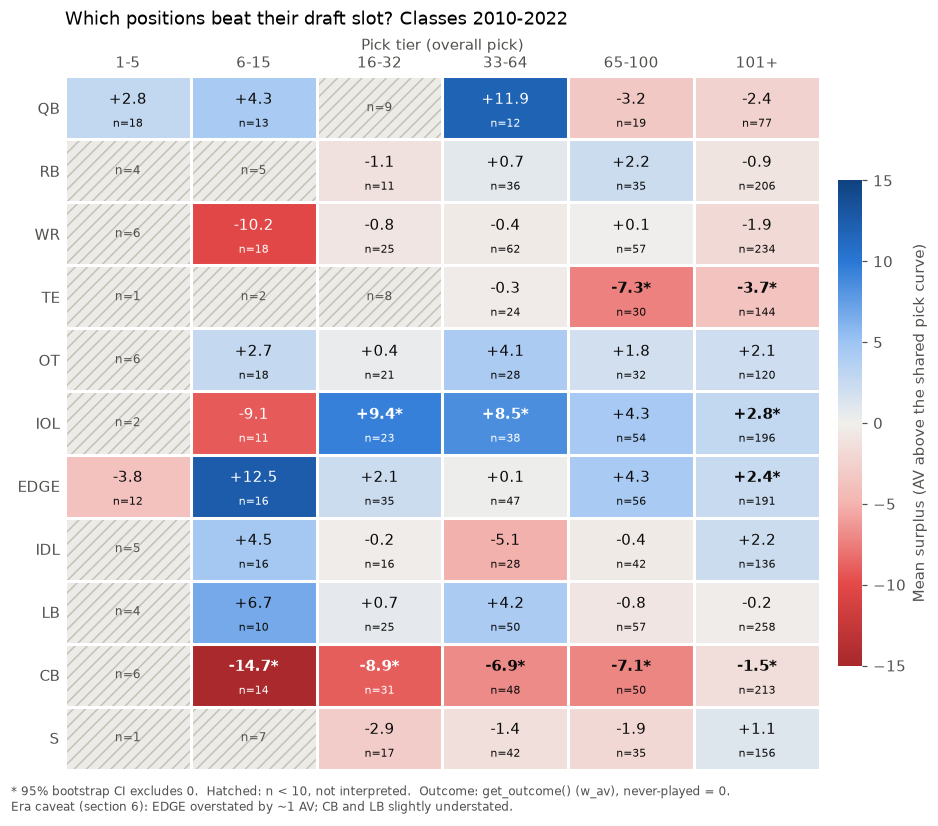

In [31]:
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(mean_g.mask(small_g).astype(float), cmap=SURPLUS_CMAP,
               vmin=-LIM, vmax=LIM, aspect='auto')

for i in range(len(POSITION_GROUPS)):
    for j in range(len(PICK_LABELS)):
        m, n = mean_g.iat[i, j], int(n_g.iat[i, j])
        if small_g.iat[i, j]:
            ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, facecolor='#ecebe7',
                                   hatch='///', edgecolor='#c3c2b7', lw=0))
            ax.text(j, i, f'n={n}', ha='center', va='center', fontsize=8, color='#52514e')
            continue
        ink = 'white' if abs(m) > 0.55 * LIM else '#0b0b0b'
        clear = clear_g.iat[i, j]
        ax.text(j, i - .13, f'{m:+.1f}' + ('*' if clear else ''), ha='center', va='center',
                fontsize=10, color=ink, weight='bold' if clear else 'normal')
        ax.text(j, i + .25, f'n={n}', ha='center', va='center', fontsize=7.5, color=ink)

# 2px white gaps between cells, no other grid
ax.set_xticks(range(len(PICK_LABELS)), PICK_LABELS)
ax.set_yticks(range(len(POSITION_GROUPS)), POSITION_GROUPS)
ax.set_xticks(np.arange(-.5, len(PICK_LABELS)), minor=True)
ax.set_yticks(np.arange(-.5, len(POSITION_GROUPS)), minor=True)
ax.grid(False)
ax.grid(which='minor', color='white', lw=2)
ax.tick_params(which='both', length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.xaxis.tick_top()
ax.set_xlabel('Pick tier (overall pick)')
ax.xaxis.set_label_position('top')

cbar = fig.colorbar(im, ax=ax, shrink=0.7, pad=0.02)
cbar.set_label('Mean surplus (AV above the shared pick curve)')
cbar.outline.set_visible(False)

ax.set_title(f'Which positions beat their draft slot? Classes {CLASS_MIN}-{CLASS_MAX}',
             loc='left', pad=34)
fig.text(0.01, 0.01,
         f'* 95% bootstrap CI excludes 0.  Hatched: n < {MIN_N}, not interpreted.  '
         'Outcome: get_outcome() (w_av), never-played = 0.\n'
         'Era caveat (section 6): EDGE overstated by ~1 AV; CB and LB slightly understated.',
         fontsize=8, color='#52514e')
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

### Which positions beat their slot?

Only **starred** cells (CI excludes 0, n ≥ 10) count as findings. Unstarred colours are
leanings at best.

| tier | clearly **beat** the slot | clearly **fell short** | leaning, not confident |
|---|---|---|---|
| 1-5 | none | none | only QB (n=18) and EDGE (n=12) are interpretable, both near 0 |
| 6-15 | none | **CB** (-14.7) | EDGE +12.5, LB +6.7, WR -10.2, IOL -9.1 |
| 16-32 | **IOL** (+9.4) | **CB** (-8.9) | |
| 33-64 | **IOL** (+8.5) | **CB** (-6.9) | QB +11.9 (n=12, CI -5 to +31) |
| 65-100 | none | **TE** (-7.3), **CB** (-7.1) | EDGE +4.3, IOL +4.3 |
| 101+ | **IOL** (+2.8), **EDGE** (+2.4) | **TE** (-3.7), **CB** (-1.5) | OT +2.1, IDL +2.2 |

**Patterns**
- **CB falls short in every interpretable tier**: 5 of 5, all starred. This is the
  strongest result in the table.
- **IOL beats its slot in rounds 1-2 and on day 3** (picks 101+). Its 6-15 cell is the
  exception (-9.1, not starred).
- **TE falls short from pick 65 on.** Its early cells are too small to read.
- **The top of the draft can't be judged by position.** 9 of 11 positions have fewer than
  10 top-5 picks in 13 years.

**Read these with three cautions** (expanded in the limitations section):
1. **AV may be part of the story.** AV credits linemen partly for games started and team
   offense, and is known to be stingy with defensive backs. "CB is always below, IOL is
   usually above" could partly be how AV *measures* those positions, not only how they
   are drafted. A position sitting consistently on one side of a single shared curve is
   exactly what that bias would look like.
2. **Era:** EDGE's +2.4 at 101+ is roughly the size of its ~1 AV era inflation (section 6),
   so treat it as weak. CB is slightly *under*stated by era, which doesn't explain a
   -7 to -15 gap.
3. **Many comparisons:** we tested 52 interpretable cells. At 95% confidence, about 2-3
   would be starred by chance alone. 11 starred cells is more than chance, and they form
   consistent patterns by position, but any **single** starred cell could be a fluke.


## 8. Held-out check: does the curve generalize to classes it hasn't seen?

So far the curve was fit on all 13 classes and then used to score those same players.
That's a little circular: each player's own outcome helped draw the line he's measured
against. Here we test the curve on **draft classes it never saw**.

Two splits:
- **Leave-one-class-out (LOCO):** fit on 12 classes, predict the 13th, repeat for each
  class. Tests "does the curve generalize to a typical new class?"
- **Time split:** fit on 2010-2018, predict 2019-2022. Tests "does it predict the
  *future*?" That's harder, because of the era effect from section 6.

How we score predictions (all in AV):
- **RMSE / MAE:** typical size of a miss (RMSE punishes big misses more).
- **R²:** share of player-to-player variation the curve explains (0 = no better than
  predicting the average for everyone, 1 = perfect).
- **Bias:** mean of (actual - predicted). Negative = the curve over-predicts.
- **Naive benchmark:** predict every player at the training classes' overall average,
  i.e. ignore the pick entirely. The curve should beat it easily.

`cross_val_expected` in `src/features/baseline.py` does the LOCO loop. It's the same
benchmark Layer 2's model will have to beat.

In [32]:
from scipy.stats import spearmanr
from src.features.baseline import cross_val_expected

df['expected_cv'] = cross_val_expected(df)

# naive benchmark: the mean outcome of the other 12 classes, ignoring pick
class_sum = df.groupby('season')['outcome'].transform('sum')
class_n = df.groupby('season')['outcome'].transform('size')
df['naive_cv'] = (df['outcome'].sum() - class_sum) / (len(df) - class_n)


def score(actual, predicted):
    """Accuracy of `predicted` against `actual` (both in AV)."""
    err = actual - predicted
    return pd.Series({
        'RMSE': np.sqrt((err ** 2).mean()),
        'MAE': err.abs().mean(),
        'R2': 1 - (err ** 2).sum() / ((actual - actual.mean()) ** 2).sum(),
        'bias': err.mean(),
        'rank corr': spearmanr(actual, predicted).correlation,
    })


pd.DataFrame({
    'curve, in-sample': score(df['outcome'], df['expected']),
    'curve, held-out (LOCO)': score(df['outcome'], df['expected_cv']),
    'naive (ignore pick)': score(df['outcome'], df['naive_cv']),
}).T.round(3)

,RMSE,MAE,R2,bias,rank corr
"curve, in-sample",16.474,11.620,0.327,-0.052,0.586
"curve, held-out (LOCO)",16.616,11.709,0.315,-0.051,0.575
naive (ignore pick),20.106,15.098,-0.003,-0.002,-0.059


### 8a. Class by class

The same scores computed separately for each held-out class.

In [33]:
per_class = (df.groupby('season')[['outcome', 'expected_cv']]
               .apply(lambda g: score(g['outcome'], g['expected_cv'])))
per_class.round(2)

,RMSE,MAE,R2,bias,rank corr
season,,,,,
2010,18.06,12.69,0.37,1.85,0.59
2011,20.52,13.70,0.35,1.69,0.60
2012,21.40,14.05,0.26,2.66,0.59
2013,17.23,12.40,0.23,0.08,0.57
2014,18.05,12.73,0.34,0.96,0.59
2015,15.88,11.76,0.33,-0.14,0.58
2016,19.00,13.28,0.28,2.50,0.55
2017,17.46,12.65,0.30,1.69,0.58
2018,15.31,10.89,0.41,2.52,0.60


### 8b. Time split: train 2010-2018, predict 2019-2022

In [34]:
TRAIN_END = 2018
train, test = df[df['season'] <= TRAIN_END], df[df['season'] > TRAIN_END]
future_curve = fit_baseline(train, max_pick=MAX_PICK)
test = test.assign(expected_future=add_surplus(test, future_curve)['expected'])

print(score(test['outcome'], test['expected_future']).round(3).to_string())
print(f"\nactual / predicted for 2019-22: "
      f"{test['outcome'].mean() / test['expected_future'].mean():.2f}")

RMSE         13.066
MAE          10.071
R2            0.152
bias         -4.749
rank corr     0.587

actual / predicted for 2019-22: 0.73


In [35]:
# where in the draft does the time-split curve miss?
(test.groupby('pick_tier', observed=True)[['outcome', 'expected_future']].mean()
     .rename(columns={'outcome': 'actual', 'expected_future': 'predicted'}).round(1).T)

pick_tier,1-5,6-15,16-32,33-64,65-100,101+
actual,37.8,33.6,25.0,21.0,15.1,7.2
predicted,59.2,49.3,36.7,27.7,21.4,9.2


### 8c. Calibration plot

Group held-out players into bins of 20 picks and plot the bin's **average prediction**
(x) against its **average actual outcome** (y). A well-calibrated curve puts the points
on the diagonal. Points below the diagonal mean the curve over-predicted.

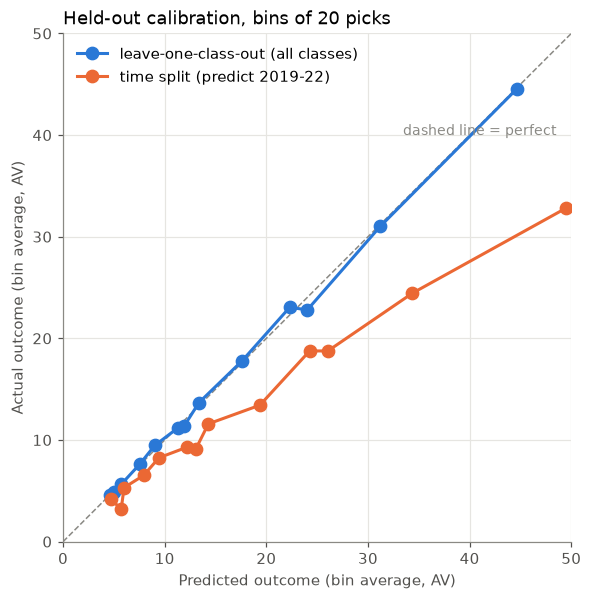

In [36]:
bins = pd.cut(df['pick_capped'], np.arange(0, MAX_PICK + 20, 20))
loco_cal = df.groupby(bins, observed=True)[['expected_cv', 'outcome']].mean()
tbins = pd.cut(test['pick_capped'], np.arange(0, MAX_PICK + 20, 20))
time_cal = test.groupby(tbins, observed=True)[['expected_future', 'outcome']].mean()

fig, ax = plt.subplots(figsize=(6, 6))
top = 5 * np.ceil(max(loco_cal.max().max(), time_cal.max().max()) / 5)
ax.plot([0, top], [0, top], color=GREY, lw=1, ls='--')
ax.plot(loco_cal['expected_cv'], loco_cal['outcome'], 'o-', color=BLUE, lw=2, ms=8,
        label='leave-one-class-out (all classes)')
ax.plot(time_cal['expected_future'], time_cal['outcome'], 'o-', color=ORANGE, lw=2, ms=8,
        label=f'time split (predict 2019-22)')
ax.text(top * 0.97, top * 0.8, 'dashed line = perfect', color=GREY, ha='right', fontsize=9)
ax.set_xlim(0, top)
ax.set_ylim(0, top)
ax.set_aspect('equal')
ax.set_xlabel('Predicted outcome (bin average, AV)')
ax.set_ylabel('Actual outcome (bin average, AV)')
ax.set_title('Held-out calibration, bins of 20 picks', loc='left')
ax.legend(frameon=False, loc='upper left')
plt.show()

### 8d. Does the heatmap change if no player helps draw his own curve?

Recompute every cell using held-out surplus (`outcome - expected_cv`) and compare it
with section 7.

In [37]:
table_cv = surplus_table(df.assign(surplus=df['outcome'] - df['expected_cv']), min_n=MIN_N)

compare = pd.DataFrame({'mean_in_sample': table['mean'], 'mean_held_out': table_cv['mean'],
                        'starred_in_sample': table['clear'], 'starred_held_out': table_cv['clear']})
print('correlation of cell means:', round(compare['mean_in_sample'].corr(compare['mean_held_out']), 4))
print('largest change in any cell (AV):',
      round((compare['mean_in_sample'] - compare['mean_held_out']).abs().max(), 2))
print('cells whose star changed:',
      (compare['starred_in_sample'] != compare['starred_held_out']).sum())

correlation of cell means: 0.9991
largest change in any cell (AV): 1.11
cells whose star changed: 0


### Held-out check: findings

**1. The curve generalizes to unseen classes with almost no loss.** Held-out RMSE is
16.6 AV vs. 16.5 in-sample, and R² is 0.315 vs. 0.327. The curve is smooth and has only
one tuning knob, so there is little room to overfit. It beats the naive "ignore the pick"
benchmark by a wide margin (RMSE 20.1, R² ≈ 0). In the calibration plot, the
leave-one-class-out points sit on the diagonal from the top bin to the bottom, so no
part of the draft is systematically mis-predicted.

**2. Pick slot alone explains about a third of player outcomes.** R² ≈ 0.32 means about
two thirds of the player-to-player variation is not explained by where a player was
picked. That's the room Layer 2 has to work with. **Benchmark Layer 2 must beat (LOCO):
RMSE 16.6, MAE 11.7, R² 0.315, rank correlation 0.575.** `cross_val_expected()` gives
these predictions directly.

**3. Ordering is stable across classes; level is not.** Rank correlation is 0.55-0.61
in *every* class, so the curve orders players equally well in every class. But
recent classes are over-predicted (bias -1 to -6 AV for 2019-22). 2022's R² is
negative purely because of that level shift (its rank correlation is a normal 0.56).
This is the section 6 era effect again, now confirmed out of sample.

**4. Predicting the future is harder for the same reason.** The 2010-18 curve
over-predicts 2019-22 by 4.7 AV on average: actual outcomes are only 73% of predicted,
in every tier. Ordering is still good (rank corr 0.59), so the curve's *shape* carries
over and only its *level* doesn't. **Implication for Layer 2:** if it's evaluated on a
time split, the pick-only benchmark must be fit on the same training years and judged on
the same metric. Rank-based metrics are fairer than RMSE/R² there, until the outcome
gets an era adjustment (FLAG FOR VINCENT, section 6).

**5. The heatmap doesn't depend on the in-sample fit.** Recomputing every cell with
held-out surplus changes cell means by at most 1.1 AV (correlation 0.999), and no
cell gains or loses its star. Section 7's conclusions stand.


## 9. Answers

### 9a. Where does the curve flatten?

The average AV a pick loses for each slot you move down, over stretches of the draft
(averaging over a stretch smooths out the small wiggles in the curve).

In [38]:
stretches = [(1, 15), (15, 32), (32, 64), (64, 100), (100, 150), (150, MAX_PICK)]
flatten = pd.DataFrame(
    [{'picks': f'{a}-{b}', 'value at start': baseline[a], 'value at end': baseline[b],
      'AV lost per pick': (baseline[a] - baseline[b]) / (b - a)} for a, b in stretches]
).set_index('picks')

total_drop = baseline[1] - baseline[MAX_PICK]
for share in [0.5, 0.75, 0.9]:
    pick = (baseline[1] - baseline >= share * total_drop).idxmax()
    print(f'{share:.0%} of the total drop in expected value is done by pick {pick}')
flatten.round(2)

50% of the total drop in expected value is done by pick 37
75% of the total drop in expected value is done by pick 97
90% of the total drop in expected value is done by pick 170


,value at start,value at end,AV lost per pick
picks,,,
1-15,55.39,39.35,1.15
15-32,39.35,31.39,0.47
32-64,31.39,23.50,0.25
64-100,23.50,15.91,0.21
100-150,15.91,11.77,0.08
150-253,11.77,4.31,0.07


**Answer:** the curve is steepest in the top 15 (about **1.2 AV lost per pick**). It
slows to about 0.5 per pick through the end of round 1, and then to about 0.2-0.25 per
pick through pick 100. **After about pick 100 it is essentially flat** (under 0.1 AV per
pick). Half of the total drop in value is gone by pick ~37, three quarters by pick ~97.
In practice, moving up 10 slots in the top 15 is worth ~12 AV, but in rounds 4-7 it's
worth less than 1 AV.

### 9b. Does one shared curve fit all positions?

If it did, every position's mean surplus (all tiers pooled) would be about 0.

In [39]:
by_pos = df.dropna(subset=['pos_group']).groupby('pos_group')['surplus']
pos_overall = pd.DataFrame({'n': by_pos.size(), 'mean_surplus': by_pos.mean()})
cis = by_pos.apply(bootstrap_ci)
pos_overall['ci_low'] = [lo for lo, hi in cis]
pos_overall['ci_high'] = [hi for lo, hi in cis]
pos_overall['clearly'] = np.select(
    [pos_overall['ci_low'] > 0, pos_overall['ci_high'] < 0], ['above', 'below'], '-')
pos_overall.sort_values('mean_surplus', ascending=False).round(2)

,n,mean_surplus,ci_low,ci_high,clearly
pos_group,,,,,
IOL,324,3.69,1.87,5.53,above
EDGE,357,2.63,0.58,4.71,above
OT,225,2.27,0.14,4.56,above
IDL,243,1.03,-0.96,3.06,-
LB,404,0.47,-0.98,2.01,-
S,258,-0.07,-1.77,1.58,-
RB,297,-0.21,-1.71,1.36,-
QB,148,-0.28,-4.26,4.14,-
WR,402,-1.69,-3.31,0.09,-


**Answer:** the shared curve fits the **average** player well (held-out, section 8), but
**not every position sits on it**. Five of eleven positions are clearly off it overall:
- **Above:** IOL (+3.7), EDGE (+2.6), OT (+2.3)
- **Below:** TE (-4.4), CB (-4.1)
- **On the curve, within noise:** QB, RB, S, LB, IDL, and WR (-1.7, borderline)

The heatmap shows the gaps are **consistent across tiers**, not driven by one cell:
CB is below in all 5 readable tiers, IOL is above in 4 of 5, and TE is at or below 0 in every
readable tier. This is what the project wants to measure (the curve is shared on purpose
so positions *can* differ), but see limitation 1: part of the gap may come from how AV
scores positions, not from draft value.

### 9c. Which positions beat their slot in each tier?

Confident results only (95% CI excludes 0, n ≥ 10); full detail in section 7.

| tier | beat the slot | fell short |
|---|---|---|
| 1-5 | none (9 of 11 positions have n < 10) | none |
| 6-15 | none | CB |
| 16-32 | IOL | CB |
| 33-64 | IOL | CB |
| 65-100 | none | TE, CB |
| 101+ | IOL, EDGE (weak: about the size of its era inflation) | TE, CB |

**Bottom line:** interior offensive linemen are the most reliable position to beat their slot
from late round 1 through day 3. Cornerbacks are the most reliable to fall short, in
every tier. The top 5 can't be judged by position with 13 classes of data.

### 9d. Limitations

1. **AV position bias.** AV is built from team-level stats split among players by
   formulas that differ by position. Offensive linemen earn AV largely for games
   started and team offense; defensive backs are known to get relatively little.
   The two strongest results (IOL above, CB below) are in the direction this bias
   would push, so they may partly reflect *measurement*, not draft value. A
   robustness check with a different outcome (e.g. `dr_av`, `seasons_started`, Pro
   Bowls) would help; that's Vincent's call.
2. **Career length and era.** `w_av` is career-to-date: classes 2019-22 are 1-6 AV below
   the curve because their careers are unfinished (section 6), and a curve fit on older
   classes over-predicts newer ones by ~27% (section 8). Mostly cancels across positions,
   but **EDGE is overstated by ~1 AV** (fewest recent players) and CB/LB slightly understated.
   No era adjustment is applied, because the outcome definition belongs to `outcome.py`.
3. **Missing outcomes.** 239 players (7.2%) have no `w_av`. All have 0 games, so they're
   filled with 0 in this notebook only (temporary). Leaving them out would have overstated
   round-7 value by ~27%.
4. **Small samples and many comparisons.** 14 of 66 cells have n < 10, including most of
   the top-5 tier. Even n = 10 gives a CI of about ±17 AV at the top. With 52 cells tested,
   2-3 stars would be expected by chance, so trust the **patterns across tiers** more than any
   single starred cell.
5. **Position labels.** 91 players with ambiguous labels (OL, DB) are excluded from the
   position table. Labels can reflect where a player *ended up*, not where he was drafted
   (e.g. Luke Joeckel, drafted as a tackle, is labelled IOL). The EDGE vs. LB boundary is an
   open team decision.
6. **Production, not cost.** "Surplus" here is production above the slot's typical return.
   It ignores contract cost, so it's not the same as economic surplus value. It also can't
   separate talent from opportunity: high picks get more playing time, which itself earns AV.

## 10. Flags for teammates

| for | flag | where |
|---|---|---|
| **Vincent (C), `outcome.py`** | `get_outcome()` returns NaN for 239 never-played players; they should be 0. Filled in this notebook only. | section 1 |
| **Vincent (C)** | Era: 2019-22 classes are 1-6 AV deflated. Recommend class-scaling (or 2010-18 only). | sections 6, 8 |
| **Vincent (C)** | AV position bias may drive the IOL/CB results; consider a robustness outcome. | section 9d |
| **Pipeline lead (A)** | 91 players with unresolved positions (OL/DB); some labels reflect a later position. | sections 7, 9d |
| **Members B + E** | EDGE vs. LB boundary still open. | `src/utils.py` |
| **Layer 2** | Pick-only benchmark (leave-one-class-out): RMSE 16.6, MAE 11.7, R² 0.315, rank corr 0.575. Use `cross_val_expected()`. | section 8 |